<a href="https://colab.research.google.com/github/Nathan-Alfredy/COU07506-labs/blob/main/COU07506_Week01_(240242455079).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

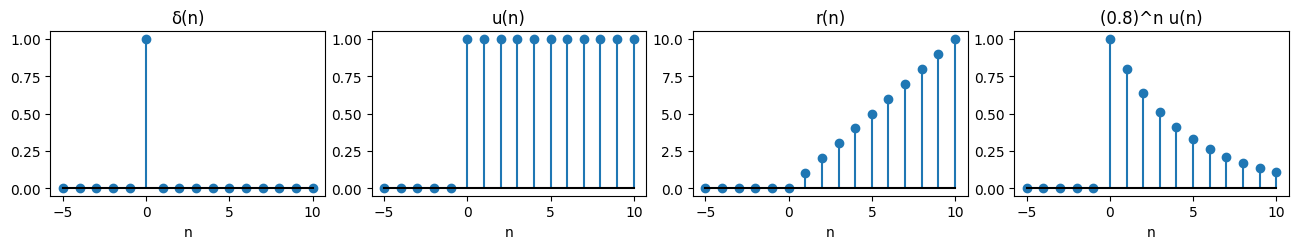

In [9]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 11)
delta = (n == 0).astype(float)  # unit impulse
step = (n >= 0).astype(float)    # unit step
ramp = n * step                 # unit ramp
expo = 0.8**n * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo], ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

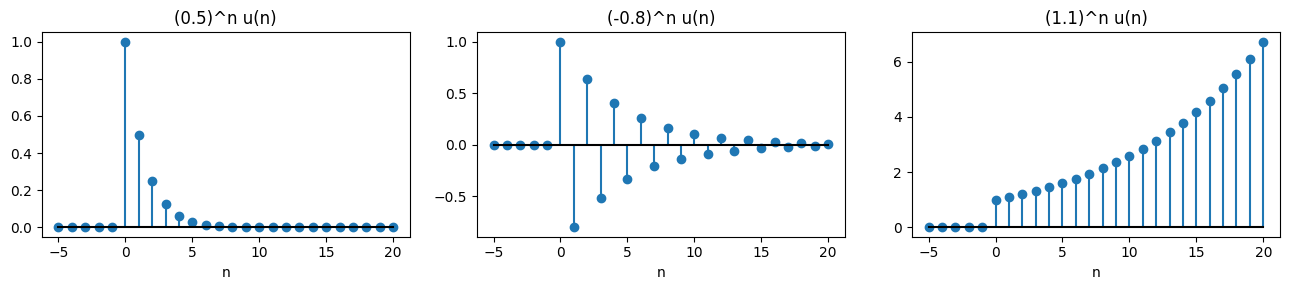

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

n = np.arange(-5, 21)
step = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a**n.astype(float)) * step
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
plt.tight_layout(); plt.show()

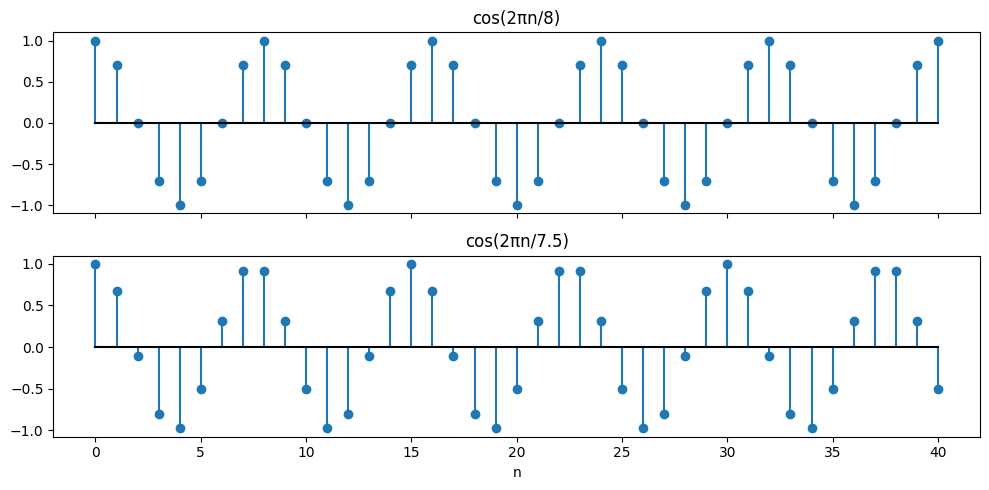

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

n = np.arange(0, 41)
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].stem(n, x1, basefmt="k-"); axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, x2, basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
plt.tight_layout(); plt.show()

Converting Helllo World.wav.mp4 to standard WAV format...
Successfully converted and saved as my_voice_converted.wav!
Sample rate: 44100 Hz
Duration: 2.46 seconds
Number of samples: 108544


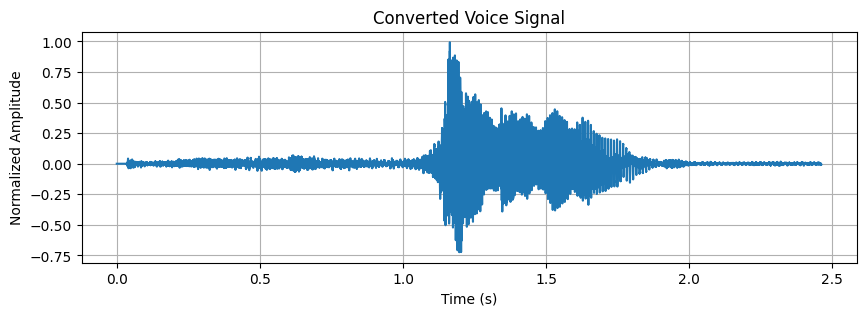

In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from pydub import AudioSegment

input_filename = "Helllo World.wav.mp4"
output_filename = "my_voice_converted.wav"

if os.path.exists(input_filename):
    try:
        # Load the MP4 audio/video file
        print(f"Converting {input_filename} to standard WAV format...")
        audio = AudioSegment.from_file(input_filename)

        # Export as a standard 16-bit PCM WAV file
        audio.export(output_filename, format="wav")
        print(f"Successfully converted and saved as {output_filename}!")

        # Verify that scipy.io.wavfile can now read it
        fs, x = wavfile.read(output_filename)

        # Convert to float normalized between [-1.0, 1.0] for signal processing
        if x.dtype == np.int16:
            x = x.astype(np.float32) / 32768.0
        elif x.dtype == np.int32:
            x = x.astype(np.float32) / 2147483648.0

        # Convert stereo to mono if needed
        if x.ndim > 1:
            x = x.mean(axis=1)

        t = np.arange(len(x)) / fs
        print(f"Sample rate: {fs} Hz")
        print(f"Duration: {len(x)/fs:.2f} seconds")
        print(f"Number of samples: {len(x)}")

        # Plot the signal
        plt.figure(figsize=(10, 3))
        plt.plot(t, x)
        plt.xlabel("Time (s)")
        plt.ylabel("Normalized Amplitude")
        plt.title("Converted Voice Signal")
        plt.grid(True)
        plt.show()

    except Exception as e:
        print(f"An error occurred during conversion: {e}")
else:
    print(f"The file '{input_filename}' was not found. Please verify the file path in your sidebar.")

fs = 44100 Hz, duration = 2.46 s, samples = 108544


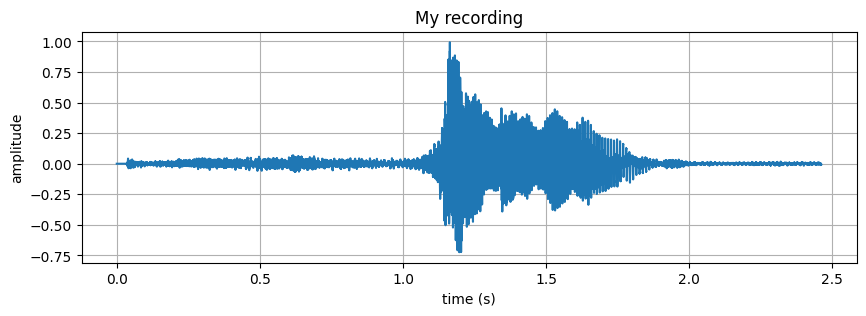

In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

# Pointing to the successfully converted WAV file
fname = "my_voice_converted.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:  # stereo -> mono
        x = x.mean(axis=1)

    # Convert integer types to normalized float [-1.0, 1.0]
    if x.dtype == np.int16:
        x = x.astype(np.float32) / 32768.0
    elif x.dtype == np.int32:
        x = x.astype(np.float32) / 2147483648.0
    else:
        x = x / np.max(np.abs(x))
else:
    # fallback test signal
    fs = 16000
    t_fallback = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t_fallback) * np.exp(-t_fallback)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.grid(True)
plt.show()

In [19]:
import IPython.display as ipd

# Path to your converted audio file
audio_file = "my_voice_converted.wav"

# Create an interactive player
print("Click play to listen to your converted voice recording:")
ipd.display(ipd.Audio(audio_file))

Click play to listen to your converted voice recording:
